# OSASUD: полные 30 минут ФПГ и потока у 21 пациента
Переработка прикреплённого ноутбука: исходный ФПГ → фильтрация → пики → пульс → сопоставление предсказаний с экспертной разметкой. Все данные встроены, **Run All** пересчитывает признаки, модели и рисунки без сети и большого pickle. Зависимости: numpy, pandas, scipy, matplotlib, scikit-learn, IPython.

Источник: maksimilli/bitrix, ветка `osasud-30min-20261030`, `research/osasud-30min/OSASUD_30min_raw.zip`; DOI 10.6084/m9.figshare.19214289.v1, CC0. SHA256 архива проверен по SHA256SUMS. Фрагменты выбраны поставщиком по времени и QC, поэтому результаты относятся к этим фрагментам, а не целым ночам.

Задача: минутное окно положительно, если ≥10 с имеют метку APNEA; отрицательно только при 60 с NONE. Гипопноэ, неизвестные метки и 1–9 с APNEA исключаются из бинарной оценки, но остаются на графиках. Это классификация минут, не выделение границ событий и не AHI. Предобработка выполняется отдельно внутри каждой минуты: данные других пациентов и соседних окон не используются. Фильтрация двунаправленная, анализ офлайн.


**Уточнение состава анализа:** встроенный архив содержит 30 пациентов, но у 9 есть пропуски ФПГ. Основное сравнение и подробные рисунки используют только 21 пациента с полными 1800 с обоих каналов. Таблица доступности перечисляет всех 30. Исходные данные остальных пациентов остаются в `all_patients`; не дополняются нулями и не склеиваются из разных интервалов. Когорта определяется по наличию данных, без просмотра меток и качества предсказаний. Это ограничение обобщаемости результатов.


In [1]:
import base64, io, zipfile, hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
    accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
plt.rcParams.update({'figure.dpi':100, 'font.size':9})
SEED=42
packed=base64.b64decode('...')

assert hashlib.sha256(packed).hexdigest() == 'e34ddb9b9a811c0c29a65ab66ecc1269f19e56f1312e1223c53ee6fb89023408'
z=zipfile.ZipFile(io.BytesIO(packed))
manifest=json.loads(z.read('manifest.json'))
patients={}
for name in sorted(z.namelist()):
    if not name.endswith('.npz'): continue
    pid=int(name.split('_')[1].split('.')[0])
    payload=z.read(name)
    assert hashlib.sha256(payload).hexdigest()==manifest['examples'][str(pid)]['sha256']
    with np.load(io.BytesIO(payload),allow_pickle=False) as f: patients[pid]={k:f[k] for k in f.files}
    d=patients[pid]
    assert d['signal_pleth'].shape==(1800,80) and d['PSG_Flow'].shape==(1800,20)
    assert np.all(np.diff(d['source_row'])==1)
    assert np.all(np.diff(d['timestamp_datetime'].astype('datetime64[s]'))==np.timedelta64(1,'s'))
print(f'Проверены {len(patients)} пациентов, {len(patients)*30} минут; архив и все NPZ: SHA256 OK')
display(pd.DataFrame([{'пациент':p,'секунд':len(d['event']),
    'метки':dict(zip(*np.unique(d['event'],return_counts=True)))} for p,d in sorted(patients.items())]))

# Основная когорта: только полные 1800 секунд обоих каналов.
# Критерий не использует метки событий или результаты модели.
all_patients=patients
availability=pd.DataFrame([{'пациент':pid,
    'доступно_секунд_ФПГ':int(np.isfinite(d['signal_pleth']).all(axis=1).sum()),
    'доступно_секунд_потока':int(np.isfinite(d['PSG_Flow']).all(axis=1).sum())}
    for pid,d in sorted(all_patients.items())])
complete_ids=[pid for pid,d in all_patients.items()
    if np.isfinite(d['signal_pleth']).all() and np.isfinite(d['PSG_Flow']).all()]
patients={pid:all_patients[pid] for pid in sorted(complete_ids)}
availability['основной_анализ']=availability['пациент'].isin(complete_ids)
print('Основной анализ: только полные 30 минут обоих сигналов;',len(patients),'пациент')
display(availability)


Проверены 30 пациентов, 900 минут; архив и все NPZ: SHA256 OK


,пациент,секунд,метки
0,1,1800,"{'APNEA-CENTRAL': 10, 'HYPOPNEA': 58, 'NONE': ..."
1,2,1800,"{'HYPOPNEA': 32, 'NONE': 1768}"
2,3,1800,"{'APNEA-OBSTRUCTIVE': 101, 'HYPOPNEA': 397, 'N..."
3,4,1800,"{'HYPOPNEA': 90, 'NONE': 1710}"
4,5,1800,"{'APNEA-OBSTRUCTIVE': 152, 'HYPOPNEA': 565, 'N..."
5,6,1800,"{'APNEA-MIXED': 18, 'APNEA-OBSTRUCTIVE': 98, '..."
6,7,1800,"{'HYPOPNEA': 85, 'NONE': 1715}"
7,8,1800,"{'APNEA-OBSTRUCTIVE': 21, 'NONE': 1779}"
8,9,1800,{'NONE': 1800}
9,10,1800,"{'HYPOPNEA': 227, 'NONE': 1573}"


Основной анализ: только полные 30 минут обоих сигналов; 21 пациент


,пациент,доступно_секунд_ФПГ,доступно_секунд_потока,основной_анализ
0,1,1530,1800,False
1,2,1003,1800,False
2,3,1800,1800,True
3,4,1755,1800,False
4,5,1800,1800,True
5,6,1800,1800,True
6,7,1577,1800,False
7,8,1800,1800,True
8,9,1339,1800,False
9,10,1800,1800,True


## Контроль качества и признаки
Непересекающиеся окна 60 с покрывают все 1800 с. QC до просмотра меток: ≥99% конечных значений обоих каналов, ненулевая дисперсия, доля повторённых соседних значений <95%. Для ФПГ дополнительно ≥20 пиков и ≥70% интервалов 0,35–2 с. Малые пропуски интерполируются только внутри окна; плохие окна не подменяются нормальными данными. Это эвристический QC, он не обнаруживает все артефакты.

ФПГ: Butterworth 4 порядка 0,4–9 Гц, 80→32 Гц с антиалиасингом, RMS-нормализация внутри минуты. Поток: Butterworth 2 порядка 0,1–3 Гц, 20 Гц. Признаки амплитуды, спектра и пульса вычисляются без экспертных меток и monitor_HR. Полярность пиков выбирается по доле физиологичных интервалов. ЧСС = 60/PPI; правильность каждого пика без ручной разметки пиков подтвердить нельзя.


**Карта QC не сортирует пациентов по качеству и не выбирает записи:** строки идут по ID 1–30, столбцы — последовательно по времени. Из архива загружены все 30 фрагментов; в основной анализ допущена только 21 полная запись. Цвет показывает пригодность минуты для общей оценки моделей, а не наличие заболевания. Исходные фрагменты были выбраны создателем архива; текущий ноутбук их не заменяет. 1800 строк временной шкалы не гарантируют 1800 секунд доступного ФПГ. Неполные фрагменты нельзя считать полными 30 минутами ФПГ.


,окон,пригодно,ФПГ_OK,поток_OK
patient,,,,
3,30,30,30,30
5,30,30,30,30
6,30,30,30,30
8,30,30,30,30
10,30,30,30,30
11,30,30,30,30
12,30,30,30,30
14,30,30,30,30
16,30,30,30,30


Всего окон: 630 QC OK: 630 неоднозначная метка: 147 для общего сравнения: 483 положительных: 70


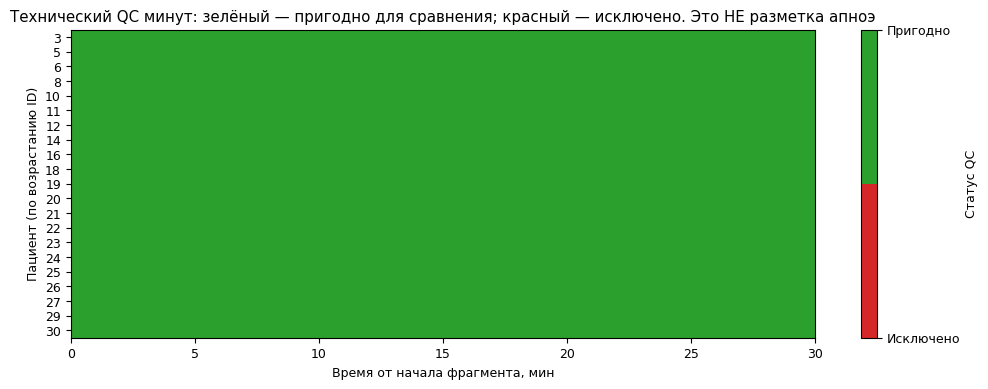

In [2]:
def fill(x):
    x=np.asarray(x,float).ravel(); ok=np.isfinite(x)
    return np.interp(np.arange(len(x)),np.flatnonzero(ok),x[ok]) if ok.any() else np.zeros_like(x)

def channel_qc(x):
    x=np.asarray(x,float).ravel(); good=np.isfinite(x)
    return bool(good.mean()>=.99 and np.std(x[good])>1e-8 and np.mean(np.diff(fill(x))==0)<.95)

def band(x,fs,lo,hi,order):
    return signal.sosfiltfilt(signal.butter(order,[lo,hi],fs=fs,btype='bandpass',output='sos'),fill(x))

def peaks_for(x):
    choices=[]
    for sign in [1,-1]:
        pk,_=signal.find_peaks(sign*x,distance=11,prominence=max(.15*np.std(x),1e-8))
        rr=np.diff(pk)/32
        score=np.mean((rr>=.35)&(rr<=2)) if len(rr) else 0
        choices.append((score,len(pk),sign,pk))
    return max(choices,key=lambda a:(a[0],a[1]))

def feats(x,fs,prefix):
    f,p=signal.welch(x,fs=fs,nperseg=min(len(x),int(10*fs)))
    amp=np.ptp(x.reshape(60,fs),axis=1)
    return {prefix+'amp':np.median(amp),prefix+'amp_cv':np.std(amp)/(np.mean(amp)+1e-10),
        prefix+'low_amp':np.mean(amp<.2*np.quantile(amp,.75)),
        prefix+'rms':np.sqrt(np.mean(x*x)),prefix+'freq':f[np.argmax(p)],
        prefix+'entropy':-np.sum((p/(p.sum()+1e-20))*np.log(p/(p.sum()+1e-20)+1e-20))}
rows=[]; processed={}; hr_pairs=[]
for pid,d in sorted(patients.items()):
    processed[pid]=[]
    for start in range(0,1800,60):
        a=d['signal_pleth'][start:start+60]; f=d['PSG_Flow'][start:start+60]
        pp=signal.resample_poly(band(a,80,.4,9,4),2,5)
        pp/=max(np.sqrt(np.mean(pp**2)),1e-10)
        flow=band(f,20,.1,3,2)
        score,_,pol,pk=peaks_for(pp); rr=np.diff(pk)/32
        valid=(rr>=.35)&(rr<=2); usable=rr[valid]
        hr=60/np.median(usable) if len(usable) else np.nan
        p_ok=channel_qc(a) and len(pk)>=20 and score>=.7
        f_ok=channel_qc(f); qc=p_ok and f_ok
        lab=d['event'][start:start+60]
        apnea=np.char.startswith(lab,'APNEA')
        known=np.all((lab=='NONE')|apnea)
        target=1 if known and apnea.sum()>=10 else (0 if np.all(lab=='NONE') else np.nan)
        row=dict(patient=pid,start_s=start,target=target,ppg_ok=p_ok,flow_ok=f_ok,qc=qc,
            apnea_s=int(apnea.sum()),missing_ppg=1-np.isfinite(a).mean(),missing_flow=1-np.isfinite(f).mean())
        row.update(feats(pp,32,'p_'));row.update(feats(flow,20,'f_'))
        row.update(p_hr=hr,p_rr_sd=np.std(usable) if len(usable)>1 else np.nan,
                   p_rr_valid=score)
        rows.append(row);processed[pid].append((pp,flow,pk,pol,hr,qc))
        hr_ref=d['monitor_HR'][start:start+60]
        ref=np.nanmedian(hr_ref) if np.isfinite(hr_ref).any() else np.nan
        if p_ok and np.isfinite(ref) and 25<ref<220 and np.isfinite(hr):hr_pairs.append((pid,start,hr,ref))
windows=pd.DataFrame(rows)
assert len(windows)==len(patients)*30 and windows.groupby('patient').size().eq(30).all()
cohort=windows[windows.qc & windows.target.notna()].copy().reset_index(drop=True)
cohort['target']=cohort.target.astype(int)
display(windows.groupby('patient').agg(окон=('qc','size'),пригодно=('qc','sum'),ФПГ_OK=('ppg_ok','sum'),поток_OK=('flow_ok','sum')))
print('Всего окон:',len(windows),'QC OK:',windows.qc.sum(),'неоднозначная метка:',windows.target.isna().sum(),
      'для общего сравнения:',len(cohort),'положительных:',cohort.target.sum())
fig,ax=plt.subplots(figsize=(12,4))
qcmap=windows.qc.to_numpy().reshape(len(patients),30)
from matplotlib.colors import ListedColormap
im=ax.imshow(qcmap,aspect='auto',cmap=ListedColormap(['#d62728','#2ca02c']),vmin=0,vmax=1,extent=[0,30,len(patients)+.5,.5])
ax.set_yticks(np.arange(1,len(patients)+1),labels=sorted(patients))
ax.set(xlabel='Время от начала фрагмента, мин',ylabel='Пациент (по возрастанию ID)',title='Технический QC минут: зелёный — пригодно для сравнения; красный — исключено. Это НЕ разметка апноэ')
cb=fig.colorbar(im,ax=ax,ticks=[0,1]);cb.ax.set_yticklabels(['Исключено','Пригодно']);cb.set_label('Статус QC');plt.show()


## Проверка на независимых пациентах
Внешняя Leave-One-Patient-Out: каждый пациент тестируется один раз, остальные используются для обучения. Внутри train — GroupKFold(3) для получения вероятностей на независимых пациентах. Фиксированная логистическая регрессия C=1; параметры не выбираются по внешнему тесту. Импутация, масштабирование и балансировка классов обучаются внутри train. Platt-калибратор обучается на внутренних OOF-вероятностях без весов классов; порог фиксирован 0,5. Для сравнения модальностей используется одна и та же когорта QC. Непригодные и неоднозначные минуты получают пропуск прогноза.


In [3]:
P=[c for c in cohort if c.startswith('p_')]
F=[c for c in cohort if c.startswith('f_')]
FEATURES={'ФПГ':P,'Поток':F,'ФПГ + поток':P+F}
y=cohort.target.to_numpy(); groups=cohort.patient.to_numpy()
def estimator():
    return make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),
        LogisticRegression(C=1,class_weight='balanced',max_iter=2000,random_state=SEED))
def logit(p):
    p=np.clip(p,1e-6,1-1e-6);return np.log(p/(1-p)).reshape(-1,1)
probs={};uncal={};audit=[]
for name,cols in FEATURES.items():
    X=cohort[cols].replace([np.inf,-np.inf],np.nan)
    out=np.full(len(y),np.nan); raw=out.copy()
    for pid in np.unique(groups):
        tr=np.flatnonzero(groups!=pid);te=np.flatnonzero(groups==pid)
        assert not set(groups[tr]) & set(groups[te])
        assert len(np.unique(y[tr]))==2
        inner=np.full(len(tr),np.nan)
        for it,iv in GroupKFold(3).split(X.iloc[tr],y[tr],groups[tr]):
            assert not set(groups[tr[it]]) & set(groups[tr[iv]])
            assert len(np.unique(y[tr[it]]))==2
            m=estimator().fit(X.iloc[tr[it]],y[tr[it]])
            inner[iv]=m.predict_proba(X.iloc[tr[iv]])[:,1]
        cal=LogisticRegression(C=1e6,max_iter=2000).fit(logit(inner),y[tr])
        m=estimator().fit(X.iloc[tr],y[tr]);raw[te]=m.predict_proba(X.iloc[te])[:,1]
        out[te]=cal.predict_proba(logit(raw[te]))[:,1]
        audit.append({'модель':name,'тестовый пациент':pid,'обучающих пациентов':len(np.unique(groups[tr])),
                      'тестовых окон':len(te),'пересечение пациентов':0})
    assert np.isfinite(out).all()
    probs[name]=out;uncal[name]=raw
    print(name,'готово')
display(pd.DataFrame(audit).head(6))

def metrics(y,p):
    pred=p>=.5;tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(ROC_AUC=roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan,
        PR_AUC_AP=average_precision_score(y,p) if y.sum()>0 else np.nan,
        Brier=brier_score_loss(y,p),Accuracy=accuracy_score(y,pred),
        Balanced_accuracy=balanced_accuracy_score(y,pred) if len(np.unique(y))==2 else np.nan,
        F1=f1_score(y,pred,zero_division=0),Sensitivity=tp/(tp+fn) if tp+fn else np.nan,
        Specificity=tn/(tn+fp) if tn+fp else np.nan)
results=pd.DataFrame({name:metrics(y,p) for name,p in probs.items()}).T
display(results.round(4))
display(pd.DataFrame({'Brier до калибровки':{k:brier_score_loss(y,v) for k,v in uncal.items()},
                      'Brier после калибровки':{k:brier_score_loss(y,v) for k,v in probs.items()}}).round(4))


ФПГ готово


Поток готово


ФПГ + поток готово


,модель,тестовый пациент,обучающих пациентов,тестовых окон,пересечение пациентов
0,ФПГ,3,20,12,0
1,ФПГ,5,20,6,0
2,ФПГ,6,20,10,0
3,ФПГ,8,20,29,0
4,ФПГ,10,20,19,0
5,ФПГ,11,20,30,0


,ROC_AUC,PR_AUC_AP,Brier,Accuracy,Balanced_accuracy,F1,Sensitivity,Specificity
ФПГ,0.1237,0.0857,0.1332,0.8551,0.5000,0.0000,0.0000,1.0000
Поток,0.9020,0.6138,0.0816,0.8861,0.6783,0.4954,0.3857,0.9709
ФПГ + поток,0.8558,0.4860,0.0973,0.8737,0.6295,0.3960,0.2857,0.9734


,Brier до калибровки,Brier после калибровки
ФПГ,0.2453,0.1332
Поток,0.1138,0.0816
ФПГ + поток,0.1344,0.0973


## ROC, PR и калибровка
Все кривые используют только внешние OOF-прогнозы. PR-AUC представлен average precision (AP, ступенчатое интегрирование). Пунктир PR — распространённость класса. Калибровка: 6 квантильных корзин. Brier меньше — лучше; идеальная калибровка лежит на диагонали.


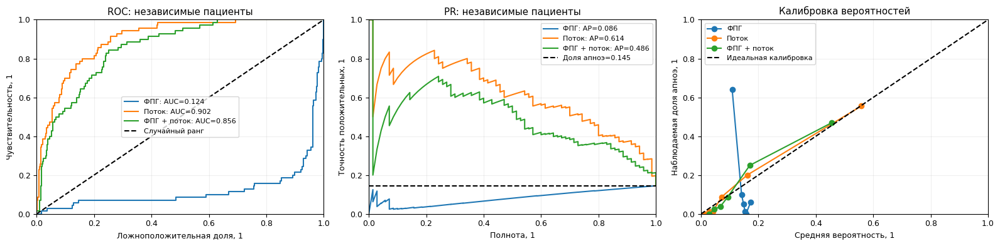

In [4]:
COLORS={'ФПГ':'#1f77b4','Поток':'#ff7f0e','ФПГ + поток':'#2ca02c'}
fig,axs=plt.subplots(1,3,figsize=(16,4))
for name,p in probs.items():
    color=COLORS[name];fpr,tpr,_=roc_curve(y,p);pr,re,_=precision_recall_curve(y,p)
    axs[0].plot(fpr,tpr,color=color,label=f'{name}: AUC={roc_auc_score(y,p):.3f}')
    axs[1].plot(re,pr,color=color,label=f'{name}: AP={average_precision_score(y,p):.3f}')
    obs,avg=calibration_curve(y,p,n_bins=6,strategy='quantile')
    axs[2].plot(avg,obs,'o-',color=color,label=name)
axs[0].plot([0,1],[0,1],'k--',label='Случайный ранг')
axs[1].axhline(y.mean(),color='k',ls='--',label=f'Доля апноэ={y.mean():.3f}')
axs[2].plot([0,1],[0,1],'k--',label='Идеальная калибровка')
for ax,title,xl,yl in zip(axs,['ROC: независимые пациенты','PR: независимые пациенты','Калибровка вероятностей'],
    ['Ложноположительная доля, 1','Полнота, 1','Средняя вероятность, 1'],
    ['Чувствительность, 1','Точность положительных, 1','Наблюдаемая доля апноэ, 1']):
    ax.set(title=title,xlabel=xl,ylabel=yl,xlim=(0,1),ylim=(0,1));ax.legend(fontsize=8);ax.grid(alpha=.2)
plt.tight_layout();plt.show()


## Доверительные интервалы и проверка улучшения
Парный кластерный bootstrap: 1000 перевыборок пациентов с возвращением, все окна выбранного пациента сохраняются вместе. Для каждой перевыборки одни и те же пациенты используются для всех моделей. 95% percentile CI условны на уже полученных OOF-прогнозах: они не учитывают полную неопределённость повторного обучения. Выборки с одним классом не используются для ROC/AP. Малое число пациентов с апноэ ограничивает точность интервалов. Разность совместной модели и ФПГ оценивается напрямую; улучшение заявляется только если CI разности исключает ноль в нужную сторону.


In [5]:
rng=np.random.default_rng(SEED);ids=np.unique(groups)
boots={k:[] for k in probs}
for _ in range(1000):
    ix=np.concatenate([np.flatnonzero(groups==p) for p in rng.choice(ids,len(ids),replace=True)])
    if len(np.unique(y[ix]))<2:continue
    for name,p in probs.items():boots[name].append(metrics(y[ix],p[ix]))
ci=[]
for name,rep in boots.items():
    bf=pd.DataFrame(rep)
    for key in results.columns:
        lo,hi=np.nanpercentile(bf[key],[2.5,97.5]);ci.append(dict(модель=name,метрика=key,оценка=results.loc[name,key],CI_low=lo,CI_high=hi))
display(pd.DataFrame(ci).round(4))
delta=pd.DataFrame(boots['ФПГ + поток'])-pd.DataFrame(boots['ФПГ'])
comparison=[]
for key in results.columns:
    lo,hi=np.nanpercentile(delta[key],[2.5,97.5])
    better=(hi<0) if key=='Brier' else (lo>0)
    comparison.append(dict(метрика=key,разность=results.loc['ФПГ + поток',key]-results.loc['ФПГ',key],
        CI_low=lo,CI_high=hi,улучшение_подтверждено=better))
print('Совместная модель минус ФПГ; Brier: отрицательная разность лучше')
display(pd.DataFrame(comparison).round(4));print('Допустимых bootstrap-выборок:',len(delta))
per_patient=[]
for pid in ids:
    ix=groups==pid
    for name,p in probs.items():per_patient.append(dict(patient=pid,model=name,n=ix.sum(),positive=y[ix].sum(),**metrics(y[ix],p[ix])))
display(pd.DataFrame(per_patient).round(3))


,модель,метрика,оценка,CI_low,CI_high
0,ФПГ,ROC_AUC,0.1237,0.0570,0.2760
1,ФПГ,PR_AUC_AP,0.0857,0.0406,0.1655
2,ФПГ,Brier,0.1332,0.0641,0.2292
3,ФПГ,Accuracy,0.8551,0.7291,0.9451
4,ФПГ,Balanced_accuracy,0.5000,0.5000,0.5000
5,ФПГ,F1,0.0000,0.0000,0.0000
6,ФПГ,Sensitivity,0.0000,0.0000,0.0000
7,ФПГ,Specificity,1.0000,1.0000,1.0000
8,Поток,ROC_AUC,0.9020,0.8114,0.9648
9,Поток,PR_AUC_AP,0.6138,0.2611,0.8361


Совместная модель минус ФПГ; Brier: отрицательная разность лучше


,метрика,разность,CI_low,CI_high,улучшение_подтверждено
0,ROC_AUC,0.7321,0.5317,0.8553,True
1,PR_AUC_AP,0.4002,0.1446,0.6862,True
2,Brier,-0.0358,-0.0934,0.0035,False
3,Accuracy,0.0186,-0.0270,0.0796,False
4,Balanced_accuracy,0.1295,0.0097,0.2609,True
5,F1,0.3960,0.0654,0.6311,True
6,Sensitivity,0.2857,0.0400,0.5635,True
7,Specificity,-0.0266,-0.0646,-0.0024,False


Допустимых bootstrap-выборок: 1000


,patient,model,n,positive,ROC_AUC,PR_AUC_AP,Brier,Accuracy,Balanced_accuracy,F1,Sensitivity,Specificity
0,3,ФПГ,12,2,0.300,0.174,0.139,0.833,0.5,0.0,0.0,1.0
1,3,Поток,12,2,0.950,0.833,0.086,0.833,0.5,0.0,0.0,1.0
2,3,ФПГ + поток,12,2,0.950,0.833,0.113,0.833,0.5,0.0,0.0,1.0
3,5,ФПГ,6,2,0.250,0.325,0.258,0.667,0.5,0.0,0.0,1.0
4,5,Поток,6,2,1.000,1.000,0.047,1.000,1.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
58,29,Поток,30,0,NaN,NaN,0.001,1.000,NaN,0.0,NaN,1.0
59,29,ФПГ + поток,30,0,NaN,NaN,0.001,1.000,NaN,0.0,NaN,1.0
60,30,ФПГ,19,7,0.321,0.348,0.285,0.632,0.5,0.0,0.0,1.0
61,30,Поток,19,7,0.869,0.810,0.296,0.632,0.5,0.0,0.0,1.0


## Исходный сигнал, обработка, пики, пульс и предсказания
Далее для **каждого из 21 пациента основной когорты** выводится полный 30-минутный обзор и отдельное увеличение первой пригодной минуты. Красные зоны — APNEA, оранжевые — HYPOPNEA, серые — другие/неизвестные метки; NONE — белый фон. Подробная экспертная разметка показана посекундно, цель модели — поминутно. Отсутствие прогноза означает QC/неоднозначную метку, а не отсутствие апноэ. Единицы исходных амплитуд не указаны в архиве и обозначены как условные; их физический масштаб не предполагается.


Ось времени и её численные деления подписаны на каждой панели. Серый фон на двух верхних панелях означает отсутствие исходного ФПГ; обработанный сигнал там показан разрывом, без подмены нулевой линией. Например, у пациента 2 исходный ФПГ отсутствует первые 797 с (13 мин 17 с); поток при этом записан с начала фрагмента. Начало фрагмента отсчитывается по общей временной шкале всех каналов.


**Источник цветной заливки — только врачебные метки event из архива.** APNEA включает центральное и обструктивное апноэ; HYPOPNEA показано отдельно. Эти типы нельзя смешивать при подсчёте эпизодов. Заголовок каждого обзора сообщает число отдельных интервалов каждого типа. Панели 6–7 показывают алгоритм, а не врачебную заливку. Красные точки на увеличении — найденные пульсовые пики; их смысл указан в собственной легенде.


### Как читать панели 5–7
5: исходная посекундная метка врача, без предсказаний. Красная линия равна 1 на APNEA, иначе 0.
6: модель получает признаки всей минуты и выдаёт одно число от 0 до 1 для этой минуты. Горизонтальный отрезок относится ко всей минуте, а не к месту максимума внутри неё. Это классификатор минут, он не оценивает начало/конец апноэ. Разрыв означает исключённую минуту: гипопноэ, смешанные/неизвестные метки или недостаточная длительность APNEA, либо QC. Отбор по меткам здесь означает, что это диагностическая визуализация оценочной выборки, а не непрерывный вывод детектора на все 30 минут.
7: отрезок 1, если вероятность модели ≥0,5, иначе 0. Чёрный крестик в центре минуты — преобразование экспертной разметки для сравнения: 1 при ≥10 секундах APNEA и отсутствии других типов событий; 0 только при целой минуте NONE. Остальные минуты исключены; крестика нет. Крестик не отмечает момент события. Например, APNEA на 11:20–11:40 даёт крестик в 11:30, но прогноз относится к 11:00–12:00 целиком. Если событие пересекло границу минут, каждая минута проверяется отдельно. Это ограничение текущей постановки, а не точный посекундный детектор.


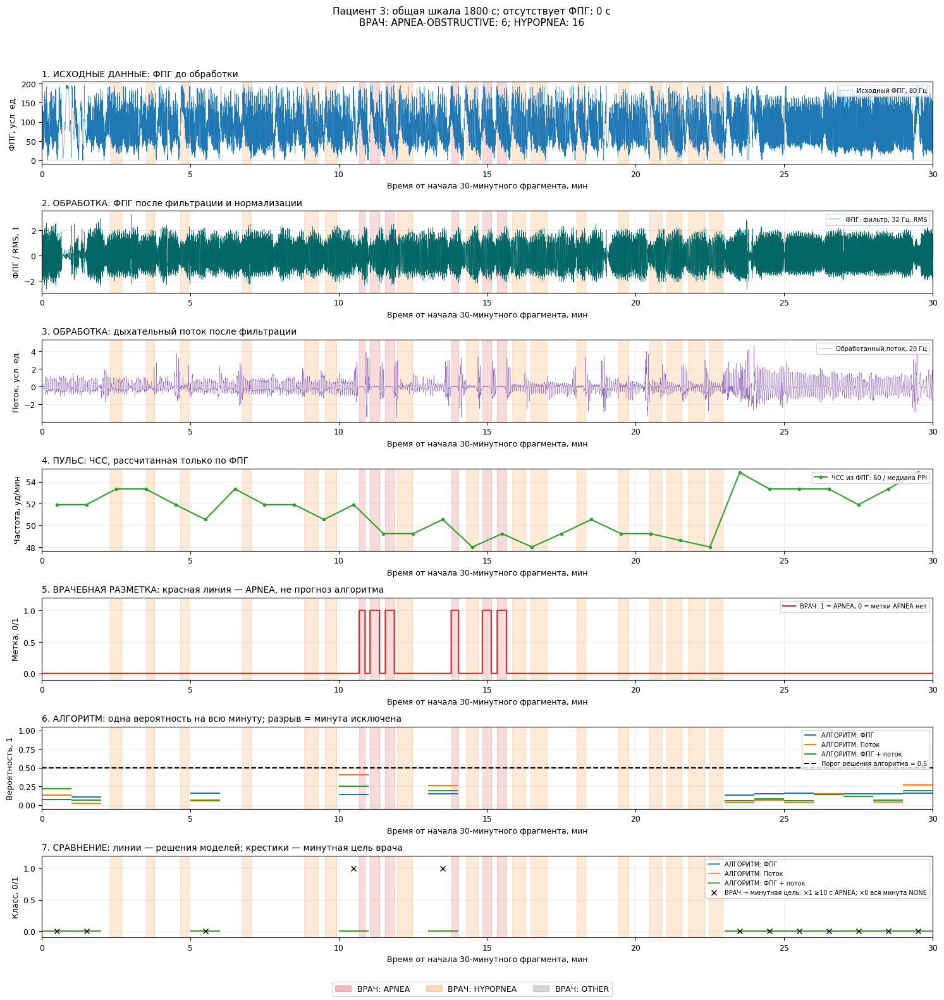

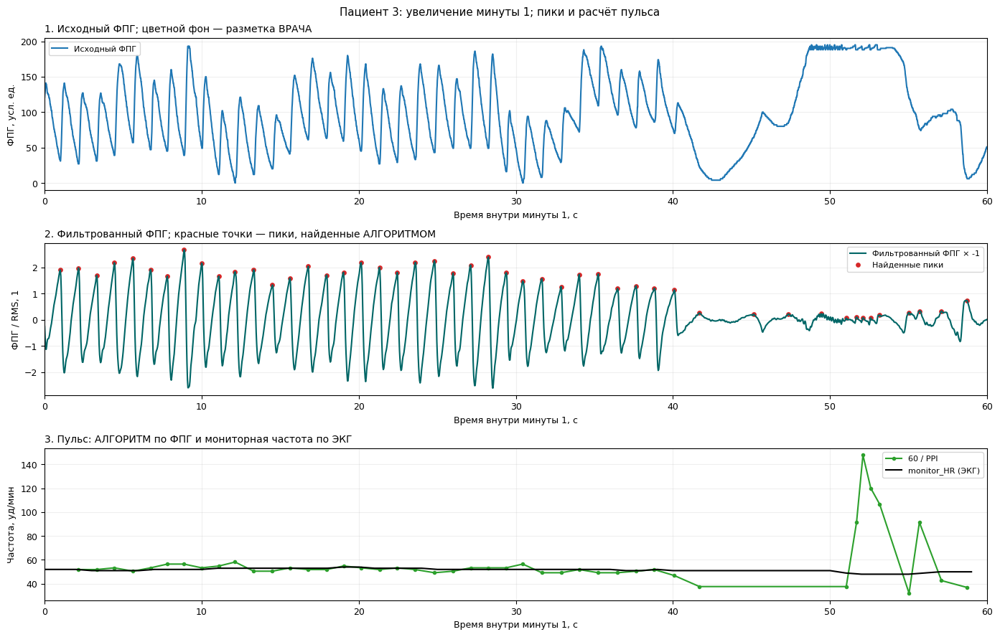

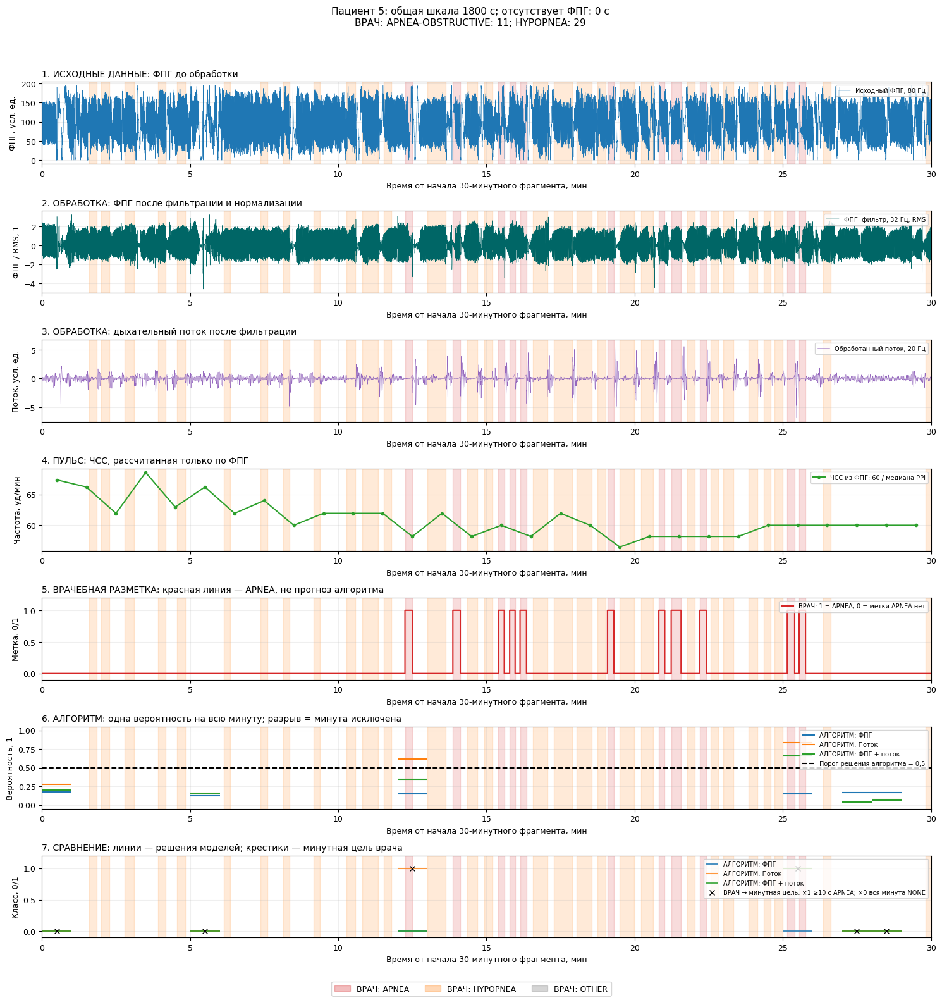

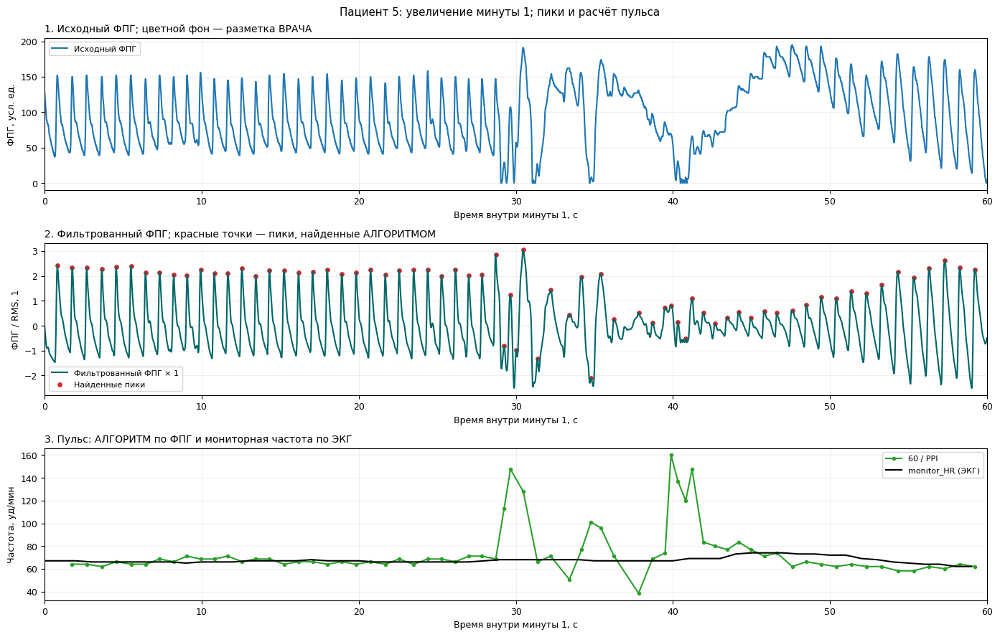

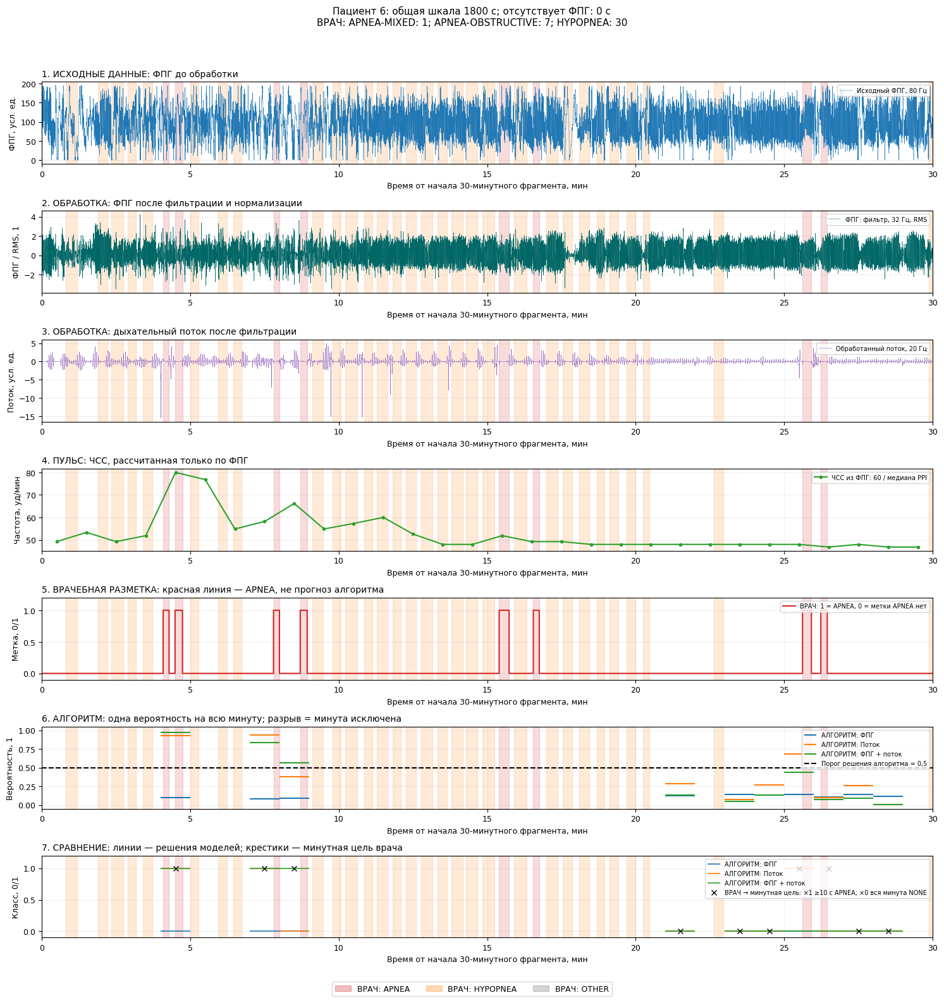

...

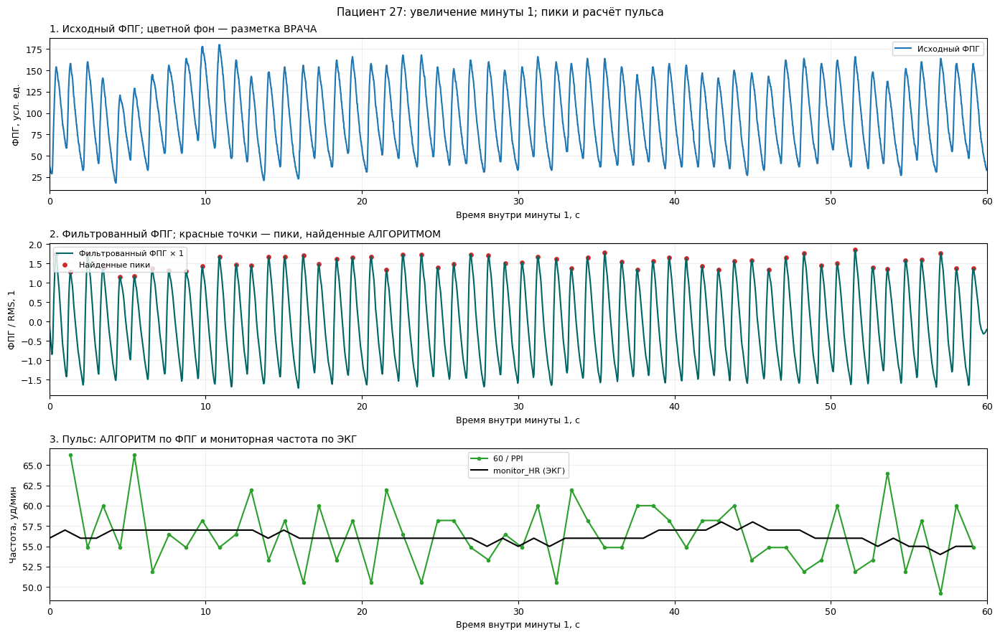

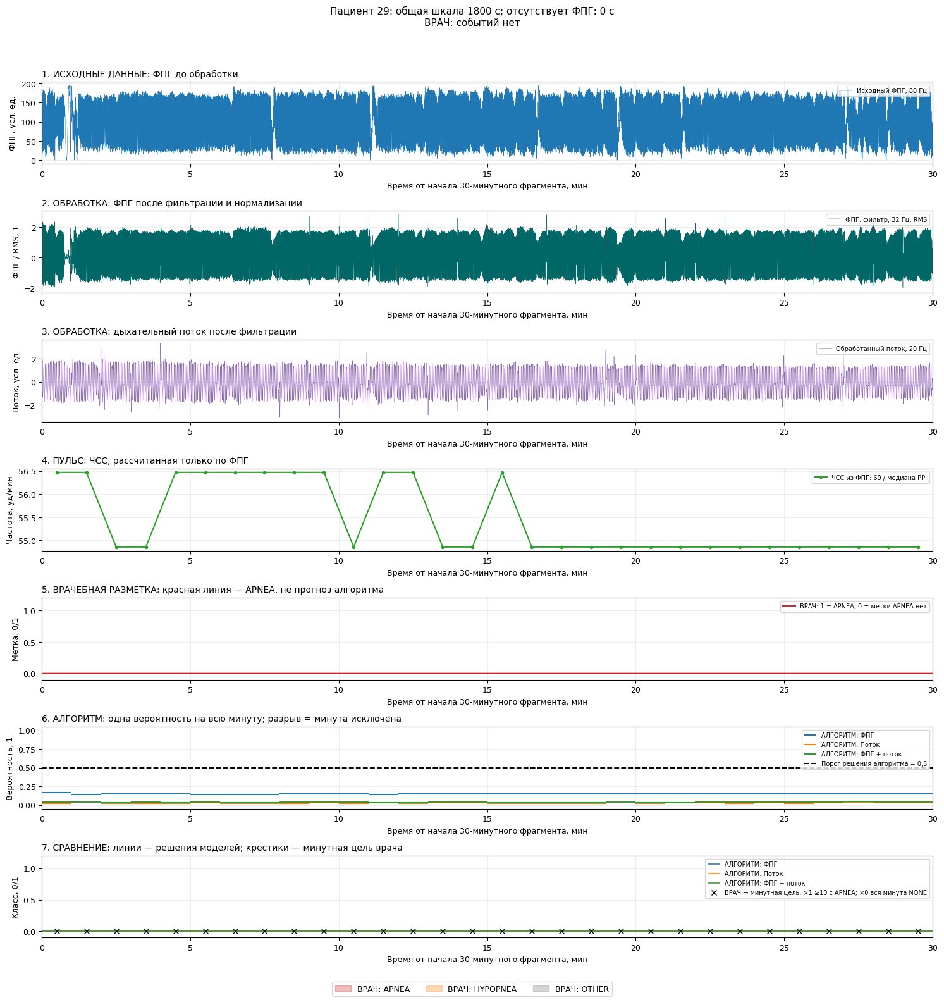

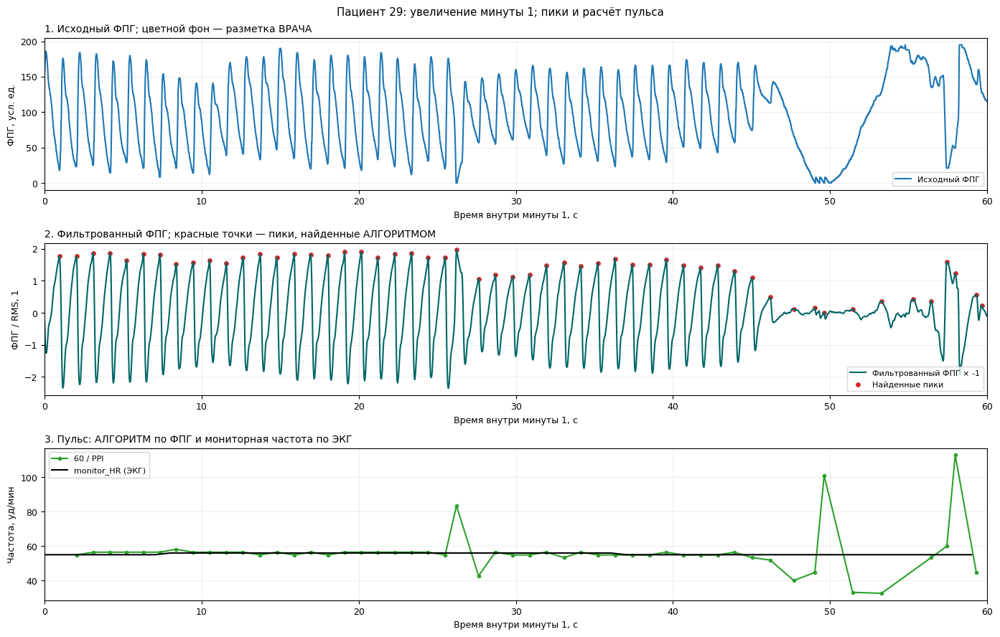

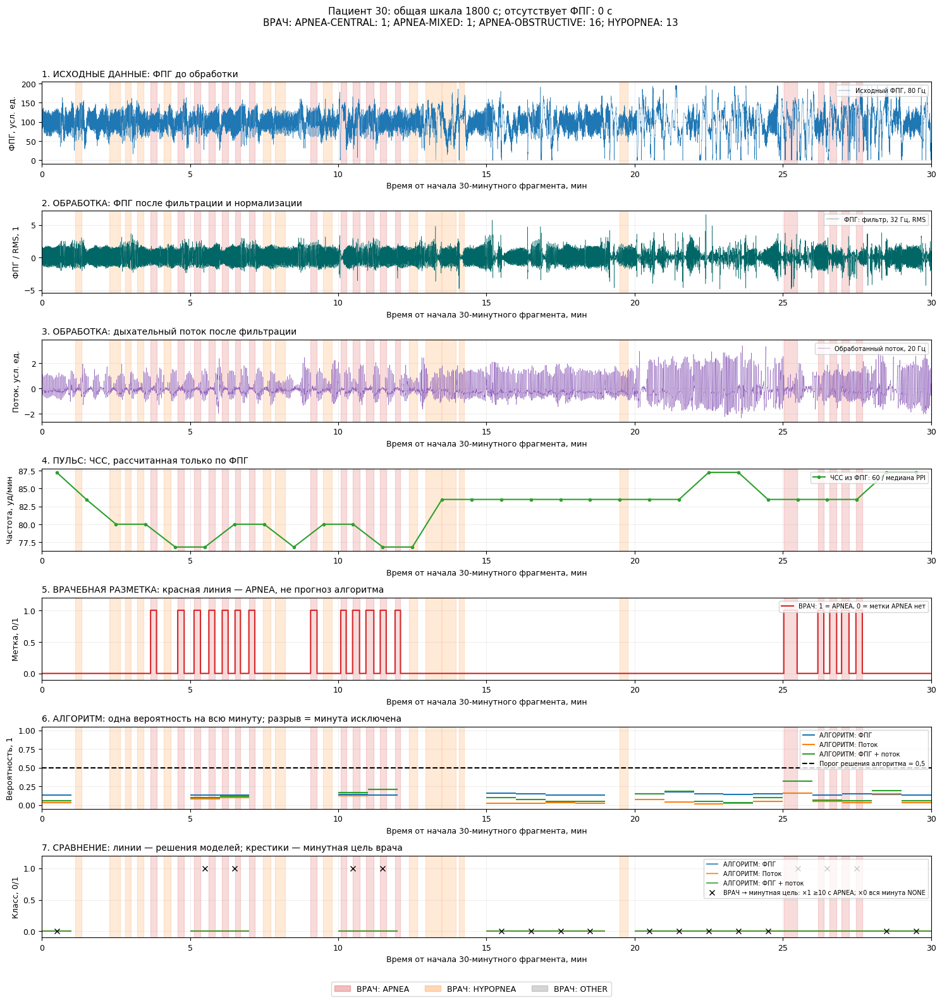

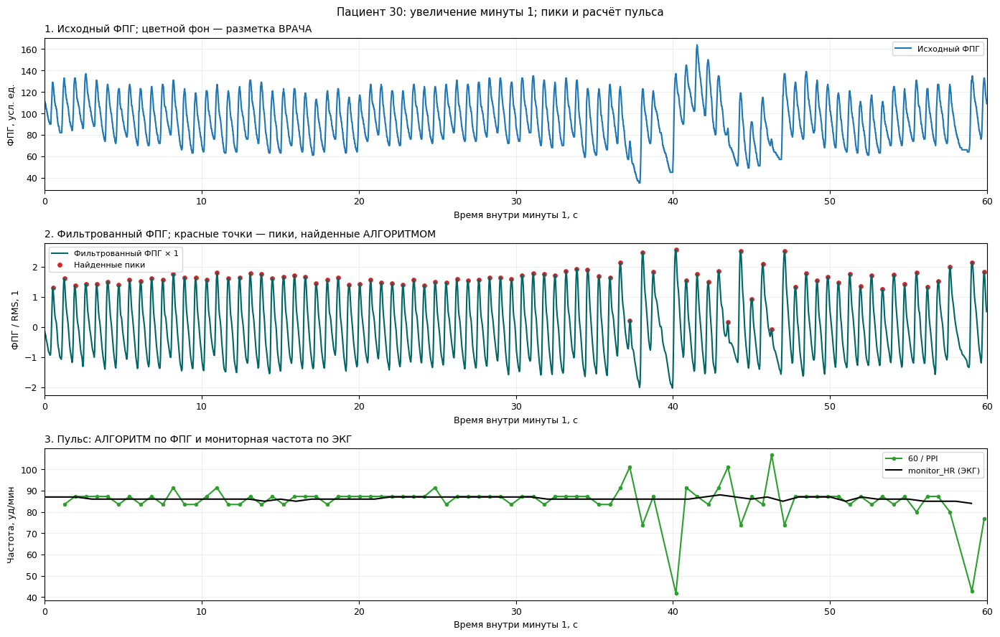

In [6]:
from matplotlib.patches import Patch
EVENT_COLORS={'APNEA':'#d62728','HYPOPNEA':'#ff7f0e','OTHER':'#777777'}
def intervals(mask):
    e=np.diff(np.r_[False,mask,False].astype(int));return zip(np.flatnonzero(e==1),np.flatnonzero(e==-1))
def shade(ax,labels,scale=60):
    masks={'APNEA':np.char.startswith(labels,'APNEA'),'HYPOPNEA':np.char.startswith(labels,'HYPOPNEA')}
    masks['OTHER']=~((labels=='NONE')|masks['APNEA']|masks['HYPOPNEA'])
    for key,mask in masks.items():
        for a,b in intervals(mask):ax.axvspan(a/scale,b/scale,color=EVENT_COLORS[key],alpha=.16)
for pid,d in sorted(patients.items()):
    counts={str(label):len(list(intervals(d['event']==label))) for label in np.unique(d['event']) if label!='NONE'}
    event_text='; '.join(f'{k}: {v}' for k,v in counts.items()) or 'событий нет'
    missing_s=int((~np.isfinite(d['signal_pleth']).all(axis=1)).sum())
    proc=processed[pid]; pp=np.concatenate([v[0] for v in proc]);flow=np.concatenate([v[1] for v in proc])
    # Не рисуем искусственные значения на месте отсутствующих исходных отсчётов.
    raw_ppg_ok=np.isfinite(d['signal_pleth']).ravel()
    pp_ok=np.isfinite(d['signal_pleth']).all(axis=1)
    flow_ok=np.isfinite(d['PSG_Flow']).all(axis=1)
    pp_plot=pp.copy();pp_plot[~np.repeat(pp_ok,32)]=np.nan
    flow_plot=flow.copy();flow_plot[~np.repeat(flow_ok,20)]=np.nan
    fig,axs=plt.subplots(7,1,figsize=(15,16),sharex=True)
    axs[0].plot(np.arange(144000)/80/60,d['signal_pleth'].ravel(),lw=.35,color='#1f77b4',label='Исходный ФПГ, 80 Гц')
    axs[0].set_ylabel('ФПГ, усл. ед.')
    axs[1].plot(np.arange(57600)/32/60,pp_plot,lw=.35,color='#006666',label='ФПГ: фильтр, 32 Гц, RMS')
    axs[1].set_ylabel('ФПГ / RMS, 1')
    axs[2].plot(np.arange(36000)/20/60,flow_plot,lw=.4,color='#9467bd',label='Обработанный поток, 20 Гц');axs[2].set_ylabel('Поток, усл. ед.')
    t=(np.arange(30)*60+30)/60
    axs[3].plot(t,[v[4] if windows[(windows.patient==pid)].iloc[i].ppg_ok else np.nan for i,v in enumerate(proc)],'o-',ms=3,color='#2ca02c',label='ЧСС из ФПГ: 60 / медиана PPI')
    axs[3].set_ylabel('Частота, уд/мин')
    obs=np.char.startswith(d['event'],'APNEA').astype(float)
    axs[4].step(np.arange(1800)/60,obs,where='post',color='#d62728',label='ВРАЧ: 1 = APNEA, 0 = метки APNEA нет')
    axs[4].set(ylabel='Метка, 0/1',ylim=(-.1,1.2))
    ct=cohort[cohort.patient==pid]
    for name,p in probs.items():
        vals=np.full(30,np.nan);vals[(ct.start_s//60).astype(int)]=p[ct.index]
        axs[5].hlines(vals,np.arange(30),np.arange(1,31),color=COLORS[name],label='АЛГОРИТМ: '+name)
        axs[6].hlines(np.where(np.isfinite(vals),vals>=.5,np.nan),np.arange(30),np.arange(1,31),color=COLORS[name],label='АЛГОРИТМ: '+name,alpha=.8)
    target=np.full(30,np.nan);target[(ct.start_s//60).astype(int)]=ct.target
    axs[6].plot(t,target,'kx',label='ВРАЧ → минутная цель: ×1 ≥10 с APNEA; ×0 вся минута NONE')
    axs[5].axhline(.5,color='black',ls='--',label='Порог решения алгоритма = 0,5');axs[5].set(ylabel='Вероятность, 1',ylim=(-.05,1.05))
    axs[6].set(ylabel='Класс, 0/1',xlabel='Время от начала 30-минутного фрагмента, мин',ylim=(-.1,1.2),xlim=(0,30))
    for ax in axs:
        shade(ax,d['event']);ax.grid(alpha=.2);ax.legend(loc='upper right',fontsize=7)
        ax.set_xlabel('Время от начала 30-минутного фрагмента, мин')
        ax.tick_params(axis='x',labelbottom=True)
    for ax in axs[:2]:
        for a0,b0 in intervals(~pp_ok):ax.axvspan(a0/60,b0/60,color='#bbbbbb',alpha=.35)
        if (~pp_ok).any():ax.text(.01,.06,'Серый фон: исходный ФПГ отсутствует; это не нулевой сигнал',transform=ax.transAxes,fontsize=8)
    for a0,b0 in intervals(~flow_ok):axs[2].axvspan(a0/60,b0/60,color='#bbbbbb',alpha=.35)
    titles=[
        '1. ИСХОДНЫЕ ДАННЫЕ: ФПГ до обработки',
        '2. ОБРАБОТКА: ФПГ после фильтрации и нормализации',
        '3. ОБРАБОТКА: дыхательный поток после фильтрации',
        '4. ПУЛЬС: ЧСС, рассчитанная только по ФПГ',
        '5. ВРАЧЕБНАЯ РАЗМЕТКА: красная линия — APNEA, не прогноз алгоритма',
        '6. АЛГОРИТМ: одна вероятность на всю минуту; разрыв = минута исключена',
        '7. СРАВНЕНИЕ: линии — решения моделей; крестики — минутная цель врача']
    for ax,title in zip(axs,titles):ax.set_title(title,loc='left',fontsize=10)
    fig.suptitle(f'Пациент {pid}: общая шкала 1800 с; отсутствует ФПГ: {missing_s} с\n'
                 f'ВРАЧ: {event_text}',fontsize=11)
    fig.legend(handles=[Patch(color=c,alpha=.3,label='ВРАЧ: '+k) for k,c in EVENT_COLORS.items()],loc='lower center',ncol=3)
    fig.tight_layout(rect=(0,.025,1,.955));plt.show()
    good=[i for i,v in enumerate(proc) if windows[windows.patient==pid].iloc[i].ppg_ok]
    minute=good[0] if good else 0
    pp,ff,pk,pol,hr,qc=proc[minute];start=minute*60
    fig,axs=plt.subplots(3,1,figsize=(14,9),sharex=True)
    detail_pp=(pol*pp).copy()
    detail_pp[~np.repeat(np.isfinite(d['signal_pleth'][start:start+60]).all(axis=1),32)]=np.nan
    axs[0].plot(np.arange(4800)/80,d['signal_pleth'][start:start+60].ravel(),color='#1f77b4',label='Исходный ФПГ');axs[0].set_ylabel('ФПГ, усл. ед.')
    axs[1].plot(np.arange(1920)/32,detail_pp,color='#006666',label=f'Фильтрованный ФПГ × {pol}')
    axs[1].scatter(pk/32,pol*pp[pk],s=15,color='#d62728',label='Найденные пики');axs[1].set_ylabel('ФПГ / RMS, 1')
    rr=np.diff(pk)/32;ok=(rr>=.35)&(rr<=2)
    axs[2].plot(pk[1:][ok]/32,60/rr[ok],'o-',ms=3,color='#2ca02c',label='60 / PPI')
    axs[2].plot(np.arange(60),d['monitor_HR'][start:start+60],color='black',label='monitor_HR (ЭКГ)')
    axs[2].set(ylabel='Частота, уд/мин',xlabel=f'Время внутри минуты {minute+1}, с',xlim=(0,60))
    for ax in axs:
        shade(ax,d['event'][start:start+60],1);ax.legend(fontsize=8);ax.grid(alpha=.2)
        ax.set_xlabel(f'Время внутри минуты {minute+1}, с')
        ax.tick_params(axis='x',labelbottom=True)
    for ax,title in zip(axs,['1. Исходный ФПГ; цветной фон — разметка ВРАЧА',
        '2. Фильтрованный ФПГ; красные точки — пики, найденные АЛГОРИТМОМ',
        '3. Пульс: АЛГОРИТМ по ФПГ и мониторная частота по ЭКГ']):ax.set_title(title,loc='left',fontsize=10)
    fig.suptitle(f'Пациент {pid}: увеличение минуты {minute+1}; пики и расчёт пульса')
    fig.tight_layout();plt.show()


Проверка ЧСС, пригодные минуты: 630
MAE, уд/мин: 1.0317094729176601 смещение, уд/мин: 0.44186368605956744


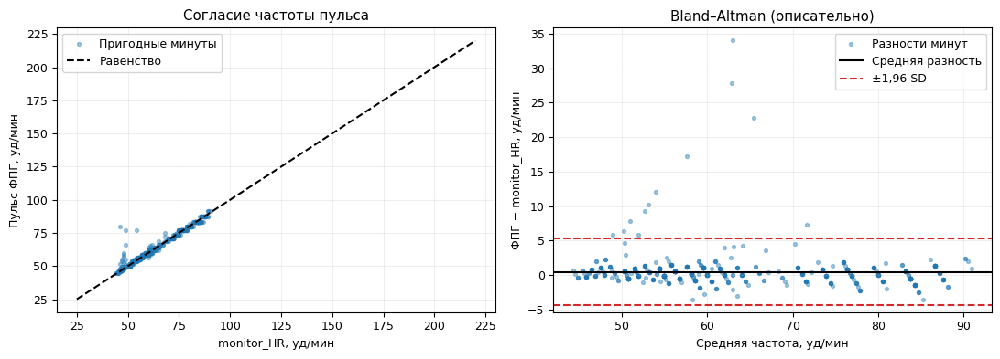

In [7]:
hp=pd.DataFrame(hr_pairs,columns=['patient','start_s','ppg_hr','monitor_hr'])
hp['error']=hp.ppg_hr-hp.monitor_hr
print('Проверка ЧСС, пригодные минуты:',len(hp))
print('MAE, уд/мин:',hp.error.abs().mean(),'смещение, уд/мин:',hp.error.mean())
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].scatter(hp.monitor_hr,hp.ppg_hr,s=8,alpha=.4,label='Пригодные минуты',color='#1f77b4')
axs[0].plot([25,220],[25,220],'k--',label='Равенство');axs[0].set(xlabel='monitor_HR, уд/мин',ylabel='Пульс ФПГ, уд/мин',title='Согласие частоты пульса')
mean=(hp.monitor_hr+hp.ppg_hr)/2;bias=hp.error.mean();sd=hp.error.std()
axs[1].scatter(mean,hp.error,s=8,alpha=.4,label='Разности минут',color='#1f77b4')
axs[1].axhline(bias,color='black',label='Средняя разность')
for v in [bias-1.96*sd,bias+1.96*sd]:axs[1].axhline(v,color='#d62728',ls='--',label='±1,96 SD' if v<bias else None)
axs[1].set(xlabel='Средняя частота, уд/мин',ylabel='ФПГ − monitor_HR, уд/мин',title='Bland–Altman (описательно)')
for ax in axs:ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.show()


## Интерпретация и ограничения
Изменение точности оценивается таблицей парных разностей и CI выше; добавление потока не предполагается автоматически полезным. Это новое сравнение модальностей на одной когорте. Сравнивать эти значения напрямую с прежним опытом на 6 мин одного пациента некорректно: изменились пациенты, длительность и единица классификации.

Отдельные пациенты могут иметь только один класс — ROC-AUC для них не определён. Общая оценка взвешивает минуты одинаково; таблица по пациентам позволяет увидеть неоднородность. Поток и экспертная разметка относятся к одному исследованию PSG, поэтому преимущество потока не доказывает переносимость на носимый ФПГ. Внешние тестовые пациенты независимы от обучения, но это внутренняя перекрёстная проверка одной базы, а не независимая внешняя клиническая валидация. QC и выбранные поставщиком 30-минутные интервалы могут смещать результаты. Фильтры и пик-детектор не являются полным воспроизведением нейросетевого метода из исходного ноутбука.

Источник описания OSASUD: Bernardini et al., Scientific Data (2022), DOI: 10.1038/s41597-022-01272-y. Все графики и числа этого ноутбука строятся заново из встроенных исходных данных. Настройки рабочей среды и секреты не включены.



Числа предыдущей когорты с неполными записями не используются. Все таблицы выше пересчитываются для 21 полного пациента.
